# Lab 3.11 — Can a rank-four adapter learn the same task?

Return to the exact pre-adaptation weights. Reuse the full-tuning data, batch order, learning rate and update budget. Change which parameters may move.

## Factor the update

For a frozen projection W, use W + BA. A maps input features into four coordinates and B maps those coordinates to output features. Initialize B to zero so the first forward pass matches the base. Which factor gets a nonzero gradient on the very first step?

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from llm_lab.experiments import loads_base, fit_adaptation, load_ckpt, adaptation, windows, loss
model,alphabet = loads_base()
model.requires_grad_(False)
class Adapter(nn.Module):
    def __init__(self, original, rank):
        super().__init__()
        self.original = original
        self.A = nn.Linear(original.in_features,rank,bias=False)
        self.B = nn.Linear(rank,original.out_features,bias=False)
        nn.init.zeros_(self.B.weight)
    def forward(self,x):
        return self.original(x) + self.B(self.A(x))
probe = torch.tensor([[1,2,3]])
before = model(probe).detach()
for block in model.h:
    block.attn.c_attn = Adapter(block.attn.c_attn,4)
torch.testing.assert_close(model(probe),before)
train,schedule,held = adaptation(alphabet)
loss(model,windows(train,schedule[0])).backward()
adapter = model.h[0].attn.c_attn
print("Initial A/B gradient norms:",adapter.A.weight.grad.norm().item(),adapter.B.weight.grad.norm().item())
model.zero_grad()

Initial A/B gradient norms: 0.0 0.07116004079580307


## Compare loss and optimizer memory

Both runs start at the same held-out loss. Full tuning updates every layer, while this adapter targets the packed attention projections. The rank measurement from Lab 3.10 describes one full update and cannot by itself predict the adaptation score.

Full trainable parameters 28576 optimizer bytes 228720 held-out loss 2.713
LoRA trainable parameters 1024 optimizer bytes 8208 held-out loss 4.002
Out[2]: PosixPath('checkpoints/lab311/adapters.npz')


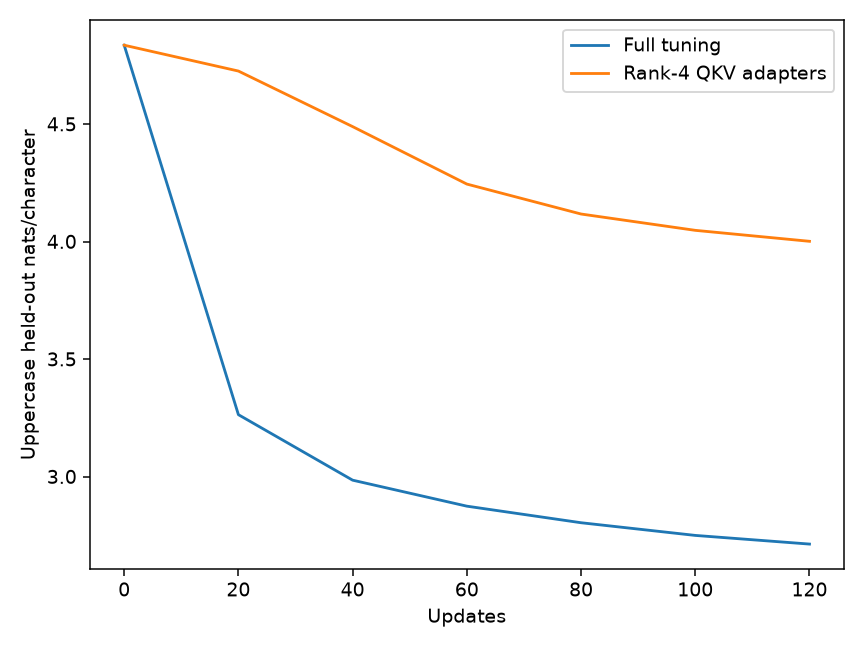

In [2]:
full = load_ckpt("checkpoints/lab310/full_tune.npz")
scores,trainable,state_bytes = fit_adaptation(model,alphabet,lr=.002)
assert abs(full["scores"][0]-scores[0]) < 1e-6
for label,n,mem,end in [("Full",full["trainable"],full["state_bytes"],full["scores"][-1]),
                        ("LoRA",trainable,state_bytes,scores[-1])]:
    print(label,"trainable parameters",int(n),"optimizer bytes",int(mem),"held-out loss",round(end,3))
plt.plot(range(0,121,20),full["scores"],label="Full tuning")
plt.plot(range(0,121,20),scores,label="Rank-4 QKV adapters")
plt.legend(); plt.xlabel("Updates"); plt.ylabel("Uppercase held-out nats/character")
show(311,"adaptation")
record(311,"adapters",scores=scores,trainable=trainable,state_bytes=state_bytes,
       **{k:v.detach() for k,v in model.named_parameters() if v.requires_grad})

## Reading the result

The rank-four adapters moved 1,024 parameters and needed 8,208 bytes of AdamW state. Full tuning moved 28,576 parameters and needed 228,720 bytes. Both improved the starting loss of 4.84. Full tuning reached 2.71 and the adapters reached 4.00. These memory figures count optimizer tensors only. The comparison uses one rank, target choice, learning rate and update budget. Which of those would you change first, and why? [LoRA paper](https://arxiv.org/abs/2106.09685)